## 소성가공 품질보증 AI 데이터셋

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

data = pd.read_csv('data/소성가공_품질보증.csv', index_col=0)
data.index = pd.to_datetime(data.index)
data

,EX5.MELT_TEMP,EX4.MELT_TEMP,EX3.MELT_TEMP,EX2.MELT_TEMP,EX1.Z1_PV,EX1.Z2_PV,EX1.Z3_PV,EX1.Z4_PV,EX1.A1_PV,EX1.A2_PV,EX1.H1_PV,EX1.H2_PV,EX1.H3_PV,EX1.H4_PV,EX1.H2O_PV,EX1.MELT_P_PV,EX1.MD_PV,EX1.MD_TQ,passorfail
date,,,,,,,,,,,,,,,,,,,
2020-10-30 00:00:04,297,222,251,267,209,219,229,239,240,239,241,240,240,40,41,0.0000,71.2215,72,0.0
2020-10-30 00:00:09,297,222,251,268,210,219,229,239,240,239,240,240,240,40,41,0.0000,71.2096,72,0.0
2020-10-30 00:00:14,297,222,251,267,210,219,229,239,240,239,240,240,240,40,41,0.0000,71.1977,72,0.0
2020-10-30 00:00:19,297,222,251,267,210,219,229,240,240,239,241,240,240,40,41,0.0000,71.1977,72,0.0
2020-10-30 00:00:24,297,222,251,267,210,219,229,239,240,239,241,240,240,40,41,0.0000,71.1977,72,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-10-30 23:59:39,296,222,252,267,215,220,230,240,240,240,240,240,240,40,42,2.8000,71.2096,72,NaN
2020-10-30 23:59:44,296,222,252,267,215,220,230,240,240,240,240,240,240,40,42,2.8438,71.2096,72,NaN
2020-10-30 23:59:49,296,222,252,267,214,220,230,240,240,240,240,240,240,40,42,2.8875,71.1858,72,NaN


<Axes: xlabel='date'>

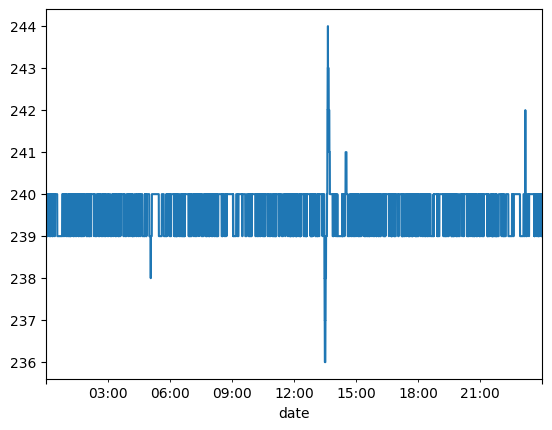

In [13]:
data.iloc[:, 12].plot()

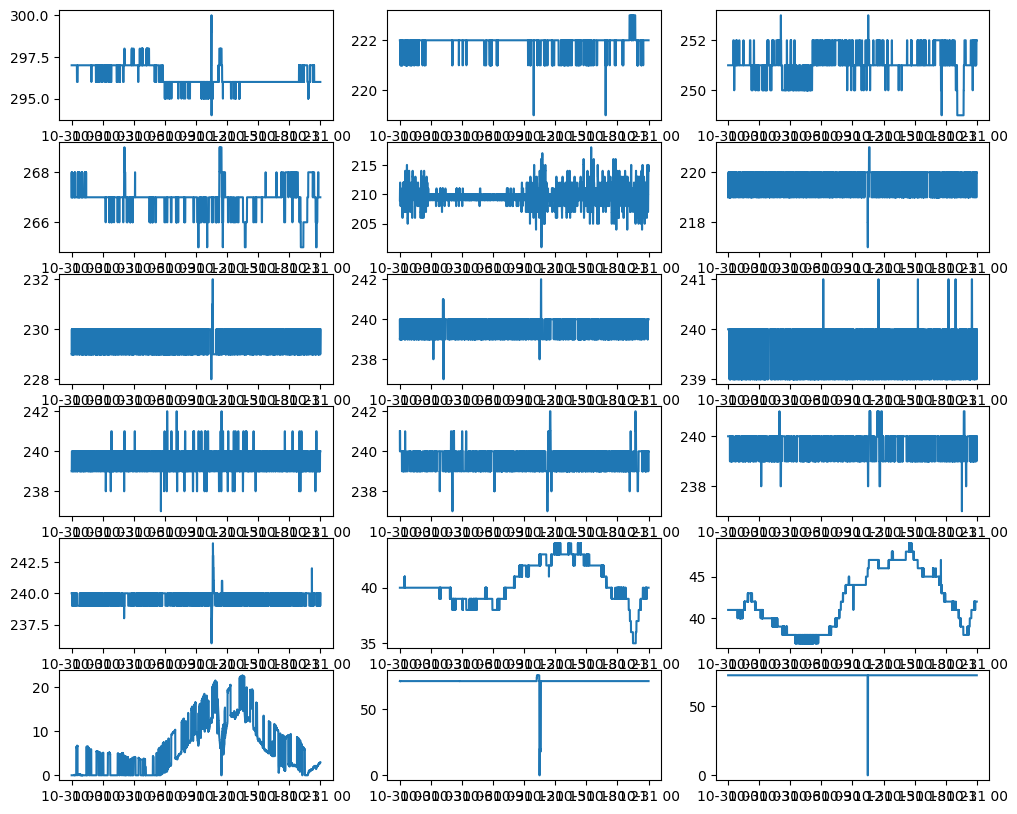

In [18]:
plt.figure(figsize=(12, 10))
for i in range(18):
    plt.subplot(6, 3, i + 1)
    plt.plot(data.iloc[:, i])
plt.show()

## 사출성형 공급망 최적화 AI 데이터셋

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

data = pd.read_csv('data/사출성형_공급망최적화.csv')
unique_products = data['Product_Number'].unique()
temp = data[data['Product_Number'] == unique_products[0]]
temp.sort_values('DateTime')

,Product_Number,T일 예정 수주량,T+1일 예정 수주량,T+2일 예정 수주량,T+3일 예정 수주량,T+4일 예정 수주량,작년 T일 예정 수주량,작년 T+1일 예정 수주량,작년 T+2일 예정 수주량,작년 T+3일 예정 수주량,작년 T+4일 예정 수주량,T일 예상 수주량,T+1일 예상 수주량,T+2일 예상 수주량,T+3일 예상 수주량,T+4일 예상 수주량,DateTime,DoW,Temperature,Humidity
183,Product_ac,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,2022-01-26 18:30,Wednesday,12.836897,35.813966
15394,Product_ac,2,0,0,0,0,0,0,0,1,0,0,0,0,0,0,2022-01-27 17:30,Thursday,10.601230,30.046817
4334,Product_ac,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,2022-01-27 6:05,Thursday,10.601230,30.046817
7048,Product_ac,2,0,0,0,0,0,0,0,1,0,0,0,0,0,0,2022-01-27 6:25,Thursday,10.601230,30.046817
440,Product_ac,2,0,0,0,0,0,0,0,1,0,0,0,0,0,0,2022-01-27 6:34,Thursday,10.601230,30.046817
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20409,Product_ac,0,0,0,2,3,7,3,0,2,0,0,8,6,0,0,2022-05-10 07:06:00,Tuesday,22.933838,27.198298
28894,Product_ac,0,0,0,2,3,7,3,0,2,0,0,8,6,0,0,2022-05-10 12:34:00,Tuesday,22.933838,27.198298
22803,Product_ac,0,0,0,2,3,7,3,0,2,0,0,8,6,0,0,2022-05-10 15:03:00,Tuesday,22.933838,27.198298
32338,Product_ac,0,0,0,2,3,7,3,0,2,0,0,8,6,0,0,2022-05-10 15:38:00,Tuesday,22.933838,27.198298


In [4]:
data.head(100).to_csv('data/sample.csv', index=False)

In [46]:
for i in range(len(unique_products)):
    temp = data[data['Product_Number'] == unique_products[i]]
    if len(temp) != 305:
        print(unique_products[i], len(temp))

Product_85 281
Product_f7 74
Product_f4 209
Product_f5 239
Product_f6 228
Product_e1 226
Product_99 610
Product_f2 240
Product_f3 142
Product_84 281
Product_87 297
Product_9e 610
Product_e9 192
Product_e4 226
Product_9b 255
Product_f8 147
Product_b1 99
Product_f1 66


In [15]:
# Dataframe에 각 제품의 "T+4일 예정 수주량" 통계 정리
stat_list = []
data = pd.read_csv('data/사출성형_공급망최적화.csv')
unique_products = data['Product_Number'].unique()
for i in range(len(unique_products)):
    temp = data[data['Product_Number'] == unique_products[i]]
    stat = [unique_products[i],
            temp['T+4일 예정 수주량'].mean(),
            temp['T+4일 예정 수주량'].median(),
            temp['T+4일 예정 수주량'].std(),
            temp['T+4일 예정 수주량'].min(),
            temp['T+4일 예정 수주량'].max()]
    stat_list.append(stat)
df_stat = pd.DataFrame(stat_list, columns=['Product_Number', 'mean', 'median', 'std', 'min', 'max'])
df_stat = df_stat.sort_values('std')
df_stat.to_csv('data/product_order_stats.csv', index=False)